PARTICLE SWARM OPTIMIZATION RESULTS

Function: Sphere
---------------------------------------------
Optimal Position:
[-1.e-06 -1.e-06  1.e-06 -2.e-06  1.e-06  1.e-06 -1.e-06  1.e-06  0.e+00
  0.e+00]
Minimum Fitness Value:
0.0000000000

Function: Rastrigin
---------------------------------------------
Optimal Position:
[ 9.95075e-01 -9.94792e-01 -9.95052e-01  9.95024e-01  7.40000e-05
  9.94814e-01 -7.00000e-06  9.94957e-01 -9.95008e-01 -9.94926e-01]
Minimum Fitness Value:
7.9596891442

Function: Rosenbrock
---------------------------------------------
Optimal Position:
[1.003772 1.010894 1.014482 1.027451 1.057116 1.115092 1.24555  1.550394
 2.391966 5.717149]
Minimum Fitness Value:
2.3423774602


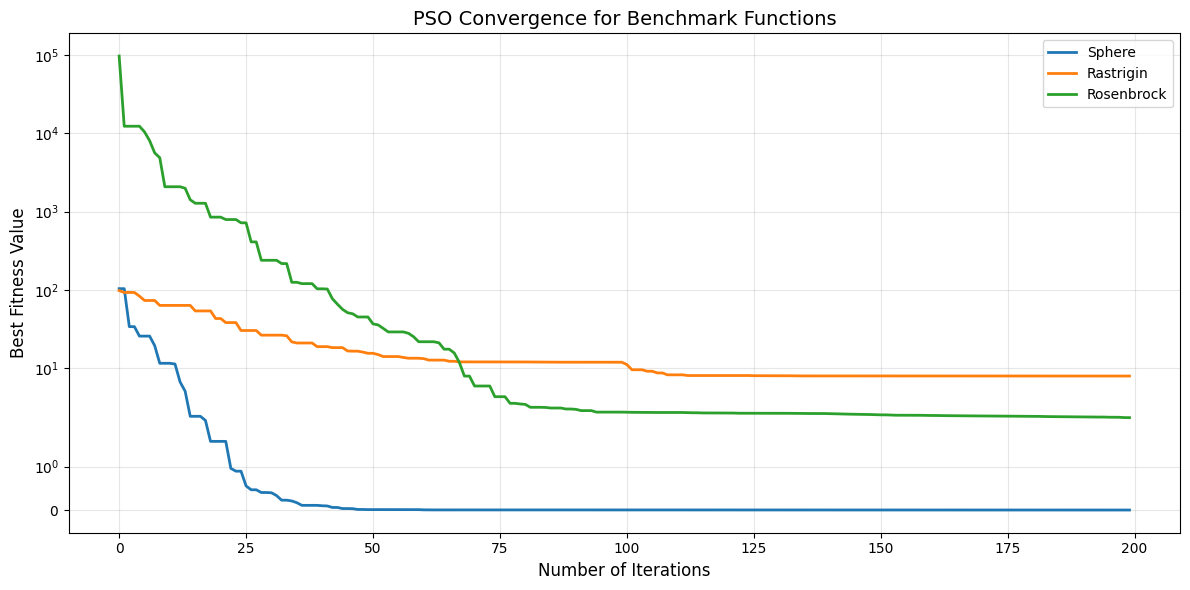

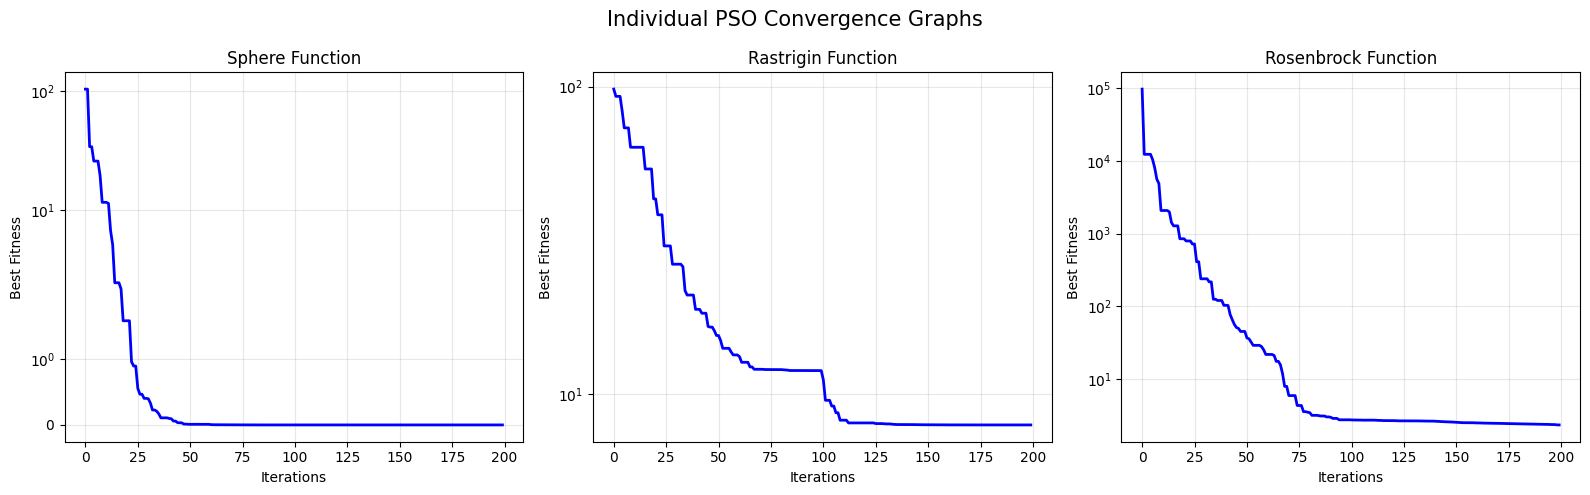

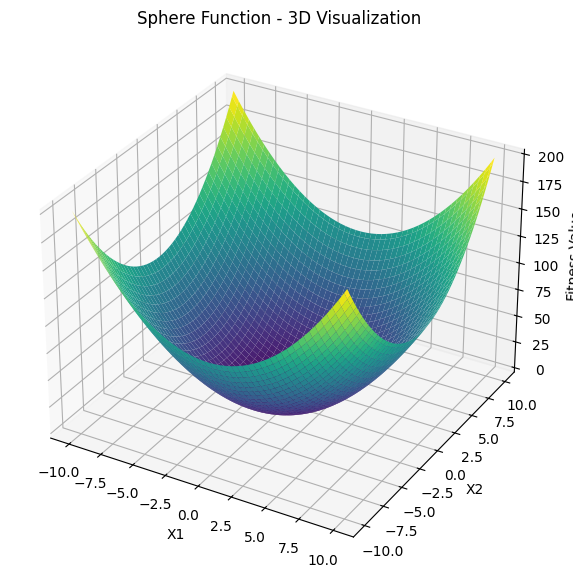



PERFORMANCE COMPARISON TABLE
            Best Fitness  Theoretical Minimum  Number of Iterations  Number of Particles
Sphere      1.198306e-11                  0.0                 200.0                 30.0
Rastrigin   7.959689e+00                  0.0                 200.0                 30.0
Rosenbrock  2.342377e+00                  0.0                 200.0                 30.0


FINAL OPTIMIZATION SUMMARY
Sphere  -> Minimum Fitness =  0.0000000000
Rastrigin  -> Minimum Fitness =  7.9596891442
Rosenbrock  -> Minimum Fitness =  2.3423774602

PSO Optimization Completed Successfully!


In [1]:

# ============================================================
# PARTICLE SWARM OPTIMIZATION (PSO) FOR FUNCTION OPTIMIZATION
# Benchmark Functions: Sphere, Rastrigin, Rosenbrock
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

# ============================================================
# 1. DEFINE OBJECTIVE FUNCTIONS
# ============================================================

# Sphere Function
def sphere(x):
    return np.sum(x**2)


# Rastrigin Function
def rastrigin(x):
    D = len(x)
    return 10 * D + np.sum(
        x**2 - 10 * np.cos(2 * np.pi * x)
    )


# Rosenbrock Function
def rosenbrock(x):
    return np.sum(
        100 * (x[1:] - x[:-1]**2)**2
        + (x[:-1] - 1)**2
    )


# ============================================================
# 2. PARTICLE SWARM OPTIMIZATION ALGORITHM
# ============================================================

def PSO(objective, dimensions, bounds,
        particles=30, iterations=200,
        w=0.7, c1=1.5, c2=1.5):

    lower, upper = bounds

    # Initialize particle positions
    X = np.random.uniform(
        lower, upper, (particles, dimensions)
    )

    # Initialize particle velocities
    V = np.random.uniform(
        -1, 1, (particles, dimensions)
    )

    # Initialize personal best positions
    pbest = X.copy()

    pbest_value = np.array([
        objective(x) for x in X
    ])

    # Initialize global best position
    best_index = np.argmin(pbest_value)

    gbest = pbest[best_index].copy()
    gbest_value = pbest_value[best_index]

    # Store convergence history
    history = []

    # PSO main loop
    for iteration in range(iterations):

        # Generate random numbers
        r1 = np.random.rand(particles, dimensions)
        r2 = np.random.rand(particles, dimensions)

        # Update velocity
        V = (
            w * V
            + c1 * r1 * (pbest - X)
            + c2 * r2 * (gbest - X)
        )

        # Update particle positions
        X = X + V

        # Apply boundary constraints
        X = np.clip(X, lower, upper)

        # Evaluate fitness
        fitness = np.array([
            objective(x) for x in X
        ])

        # Update personal best
        improved = fitness < pbest_value

        pbest[improved] = X[improved]
        pbest_value[improved] = fitness[improved]

        # Update global best
        best_index = np.argmin(pbest_value)

        if pbest_value[best_index] < gbest_value:
            gbest_value = pbest_value[best_index]
            gbest = pbest[best_index].copy()

        # Record best fitness
        history.append(gbest_value)

    return gbest, gbest_value, history


# ============================================================
# 3. DEFINE EXPERIMENTAL PARAMETERS
# ============================================================

dimensions = 10
particles = 30
iterations = 200

# Define benchmark functions and search boundaries
functions = {
    "Sphere": (sphere, (-10, 10)),
    "Rastrigin": (rastrigin, (-5.12, 5.12)),
    "Rosenbrock": (rosenbrock, (-5, 10))
}


# ============================================================
# 4. RUN PSO FOR ALL FUNCTIONS
# ============================================================

results = {}
histories = {}

print("=" * 65)
print("PARTICLE SWARM OPTIMIZATION RESULTS")
print("=" * 65)

for name, (func, bounds) in functions.items():

    best_position, best_value, history = PSO(
        objective=func,
        dimensions=dimensions,
        bounds=bounds,
        particles=particles,
        iterations=iterations
    )

    results[name] = {
        "Best Fitness": best_value,
        "Best Position": best_position
    }

    histories[name] = history

    print("\nFunction:", name)
    print("-" * 45)
    print("Optimal Position:")
    print(np.round(best_position, 6))
    print("Minimum Fitness Value:")
    print("{:.10f}".format(best_value))


# ============================================================
# 5. DISPLAY CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(12, 6))

for name, history in histories.items():
    plt.plot(history, label=name, linewidth=2)

plt.xlabel("Number of Iterations", fontsize=12)
plt.ylabel("Best Fitness Value", fontsize=12)
plt.title("PSO Convergence for Benchmark Functions",
          fontsize=14)

plt.yscale("symlog")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 6. DISPLAY INDIVIDUAL CONVERGENCE GRAPHS
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, history) in zip(axes, histories.items()):

    ax.plot(history, color="blue", linewidth=2)

    ax.set_title(name + " Function")
    ax.set_xlabel("Iterations")
    ax.set_ylabel("Best Fitness")
    ax.set_yscale("symlog")
    ax.grid(True, alpha=0.3)

plt.suptitle("Individual PSO Convergence Graphs",
             fontsize=15)

plt.tight_layout()
plt.show()


# ============================================================
# 7. DISPLAY SPHERE FUNCTION 3D GRAPH
# ============================================================

x = np.linspace(-10, 10, 100)
y = np.linspace(-10, 10, 100)

X, Y = np.meshgrid(x, y)

Z = X**2 + Y**2

fig = plt.figure(figsize=(10, 7))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(
    X, Y, Z,
    cmap="viridis",
    edgecolor="none"
)

ax.set_title("Sphere Function - 3D Visualization")
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("Fitness Value")

plt.show()


# ============================================================
# 8. COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame({
    name: {
        "Best Fitness": results[name]["Best Fitness"],
        "Theoretical Minimum": 0,
        "Number of Iterations": iterations,
        "Number of Particles": particles
    }
    for name in results
}).T

print("\n")
print("=" * 65)
print("PERFORMANCE COMPARISON TABLE")
print("=" * 65)

print(comparison.to_string())


# ============================================================
# 9. FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 65)
print("FINAL OPTIMIZATION SUMMARY")
print("=" * 65)

for name in results:

    value = results[name]["Best Fitness"]

    print(
        name,
        " -> Minimum Fitness = ",
        "{:.10f}".format(value)
    )

print("\nPSO Optimization Completed Successfully!")
